**## Import Libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

**## Load Dataset**

In [3]:
df = pd.read_csv("/content/Task17_Monthly_Sales_Dataset.csv")

df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Sales"] = pd.to_numeric(
    df["Sales"], errors="coerce"
)

df = df.dropna(subset=["Order Date", "Sales"])

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (600, 8)


,Order ID,Order Date,Product,Category,Region,Quantity,Unit Price,Sales
0,ORD-10107,2025-01-01,Printer Paper,Office Supplies,North,3,11.91,35.73
1,ORD-10321,2025-01-01,Notebook Pack,Office Supplies,North,5,9.63,48.15
2,ORD-10127,2025-01-02,Keyboard,Technology,North,7,27.84,194.88
3,ORD-10283,2025-01-02,Headphones,Technology,South,2,63.93,127.86
4,ORD-10508,2025-01-02,Desk Organizer,Office Supplies,West,2,17.94,35.88


**## Display Dataset**

In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order ID    600 non-null    object        
 1   Order Date  600 non-null    datetime64[ns]
 2   Product     600 non-null    object        
 3   Category    600 non-null    object        
 4   Region      600 non-null    object        
 5   Quantity    600 non-null    int64         
 6   Unit Price  600 non-null    float64       
 7   Sales       600 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 37.6+ KB

Missing Values:
Order ID      0
Order Date    0
Product       0
Category      0
Region        0
Quantity      0
Unit Price    0
Sales         0
dtype: int64


**## Monthly Sales Summary**

In [5]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly_sales = (
    df.groupby("Month", as_index=False)["Sales"]
      .sum()
)

monthly_sales["Month"] = monthly_sales["Month"].astype(str)

monthly_sales["Sales"] = monthly_sales["Sales"].round(2)

print("Monthly Sales Summary:")
display(monthly_sales)

Monthly Sales Summary:


,Month,Sales
0,2025-01,10443.48
1,2025-02,7868.59
2,2025-03,12759.79
3,2025-04,11823.23
4,2025-05,12675.44
5,2025-06,12233.40
6,2025-07,13022.08
7,2025-08,11197.86
8,2025-09,7661.84
9,2025-10,12048.95


**## Line Chart**

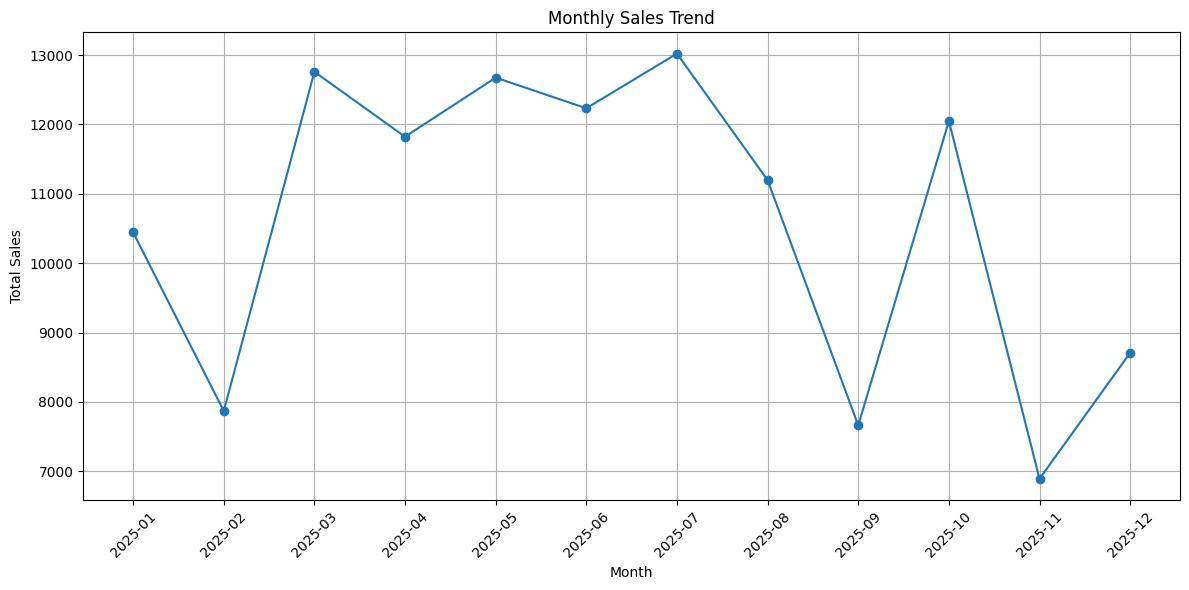

In [6]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**## Save Monthly Sales Summary**

In [7]:
monthly_sales.to_csv(
    "/content/monthly_sales_summary.csv",
    index=False
)

print("Monthly summary saved successfully!")

Monthly summary saved successfully!


**## Download Monthly Sales CSV**

In [8]:
from google.colab import files

files.download("monthly_sales_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**## Download Line Chart**

In [9]:
files.download("monthly_sales_trend.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>